In [16]:
import pandas as pd
from pathlib import Path

# Folder containing the extracted CSV files
data_folder = Path("fssai_food_safety_synthetic_project")

businesses = pd.read_csv( "food_businesses.csv")
raids = pd.read_csv( "food_raids.csv")
samples = pd.read_csv( "food_samples.csv")
violations = pd.read_csv( "violations.csv")
enforcement = pd.read_csv("enforcement_actions.csv")

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [17]:

datasets = {
    "Businesses": businesses,
    "Raids": raids,
    "Samples": samples,
    "Violations": violations,
    "Enforcement": enforcement
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Rows and columns:", df.shape)
    print(df.head(3))



--- Businesses ---
Rows and columns: (500, 8)
  business_id                     business_name       business_type  \
0       B0001  Bengaluru Street Food Vendor 001  Street Food Vendor   
1       B0002                  Nashik Dairy 002               Dairy   
2       B0003         Pune Grocery Retailer 003    Grocery Retailer   

        city        state licence_status risk_category business_start_date  
0  Bengaluru    Karnataka       Licensed        Medium          2020-12-09  
1     Nashik  Maharashtra       Licensed           Low          2015-05-11  
2       Pune  Maharashtra     Unlicensed           Low          2017-08-13  

--- Raids ---
Rows and columns: (1200, 7)
  raid_id business_id   raid_date            raid_reason inspection_team_id  \
0  R00001       B0006  2022-01-01     Routine Inspection           TEAM-003   
1  R00002       B0076  2022-01-02  Risk-Based Inspection           TEAM-005   
2  R00003       B0345  2022-01-02     Consumer Complaint           TEAM-021   



In [18]:

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    
    
    
# Check unique IDs and data types

id_columns = {
    "Businesses": (businesses, "business_id"),
    "Raids": (raids, "raid_id"),
    "Samples": (samples, "sample_id"),
    "Violations": (violations, "violation_id"),
    "Enforcement": (enforcement, "action_id")
}

for name, (df, id_col) in id_columns.items():
    print(f"\n--- {name} ---")
    print("Duplicate IDs:", df[id_col].duplicated().sum())
    print("\nColumn data types:")
    print(df.dtypes)




--- Businesses ---
Missing values: 0
Duplicate rows: 0

--- Raids ---
Missing values: 0
Duplicate rows: 0

--- Samples ---
Missing values: 0
Duplicate rows: 0

--- Violations ---
Missing values: 0
Duplicate rows: 0

--- Enforcement ---
Missing values: 0
Duplicate rows: 0

--- Businesses ---
Duplicate IDs: 0

Column data types:
business_id            object
business_name          object
business_type          object
city                   object
state                  object
licence_status         object
risk_category          object
business_start_date    object
dtype: object

--- Raids ---
Duplicate IDs: 0

Column data types:
raid_id               object
business_id           object
raid_date             object
raid_reason           object
inspection_team_id    object
raid_outcome          object
follow_up_required    object
dtype: object

--- Samples ---
Duplicate IDs: 0

Column data types:
sample_id                 object
raid_id                   object
food_category             o

In [19]:

# Convert date columns to datetime

date_columns = {
    "Businesses": (businesses, ["business_start_date"]),
    "Raids": (raids, ["raid_date"]),
    "Samples": (samples, ["sample_collection_date"]),
    "Violations": (violations, []),
    "Enforcement": (enforcement, ["action_date"])
}

for name, (df, cols) in date_columns.items():
    for col in cols:
        df[col] = pd.to_datetime(df[col], errors="coerce")

    print(f"\n{name}")
    print(df[cols].dtypes if cols else "No date columns")
    

    
# 1. Check invalid dates
for name, (df, cols) in date_columns.items():
    for col in cols:
        print(f"{name} - {col}: {df[col].isna().sum()} invalid dates")

# 2. Check foreign-key relationships
checks = {
    "Raids -> Businesses": (
        raids, "business_id", businesses, "business_id"
    ),
    "Samples -> Raids": (
        samples, "raid_id", raids, "raid_id"
    ),
    "Violations -> Raids": (
        violations, "raid_id", raids, "raid_id"
    ),
    "Enforcement -> Raids": (
        enforcement, "raid_id", raids, "raid_id"
    )
}

for name, (child, child_key, parent, parent_key) in checks.items():
    unmatched = (~child[child_key].isin(parent[parent_key])).sum()
    print(f"{name}: {unmatched} unmatched records")




Businesses
business_start_date    datetime64[ns]
dtype: object

Raids
raid_date    datetime64[ns]
dtype: object

Samples
sample_collection_date    datetime64[ns]
dtype: object

Violations
No date columns

Enforcement
action_date    datetime64[ns]
dtype: object
Businesses - business_start_date: 0 invalid dates
Raids - raid_date: 0 invalid dates
Samples - sample_collection_date: 0 invalid dates
Enforcement - action_date: 0 invalid dates
Raids -> Businesses: 0 unmatched records
Samples -> Raids: 0 unmatched records
Violations -> Raids: 0 unmatched records
Enforcement -> Raids: 0 unmatched records


In [20]:

# 1. Number of raids by state
raids_by_state = (
    raids.merge(
        businesses[["business_id", "state"]],
        on="business_id",
        how="left"
    )
    .groupby("state")
    .size()
    .sort_values(ascending=False)
)

print("Raids by State:")
print(raids_by_state)

# 2. Raids by business type
raids_by_type = (
    raids.merge(
        businesses[["business_id", "business_type"]],
        on="business_id",
        how="left"
    )
    .groupby("business_type")
    .size()
    .sort_values(ascending=False)
)

print("\nRaids by Business Type:")
print(raids_by_type)

# 3. Monthly raid trend
raids["raid_month"] = raids["raid_date"].dt.to_period("M")

monthly_raids = raids.groupby("raid_month").size()

print("\nFirst 12 Months:")
print(monthly_raids.head(12))


Raids by State:
state
Maharashtra       266
Uttar Pradesh     180
Karnataka         134
Telangana         108
Delhi              98
Tamil Nadu         98
Madhya Pradesh     92
Gujarat            85
West Bengal        77
Rajasthan          62
dtype: int64

Raids by Business Type:
business_type
Restaurant                    202
Street Food Vendor            196
Grocery Retailer              158
Packaged Food Manufacturer    127
Dairy                         112
Bakery                        108
Sweet Shop                    100
Caterer                        74
Meat/Fish Retailer             64
Warehouse/Distributor          59
dtype: int64

First 12 Months:
raid_month
2022-01    33
2022-02    20
2022-03    18
2022-04    13
2022-05    21
2022-06    19
2022-07    26
2022-08    20
2022-09    18
2022-10    21
2022-11    23
2022-12    18
Freq: M, dtype: int64


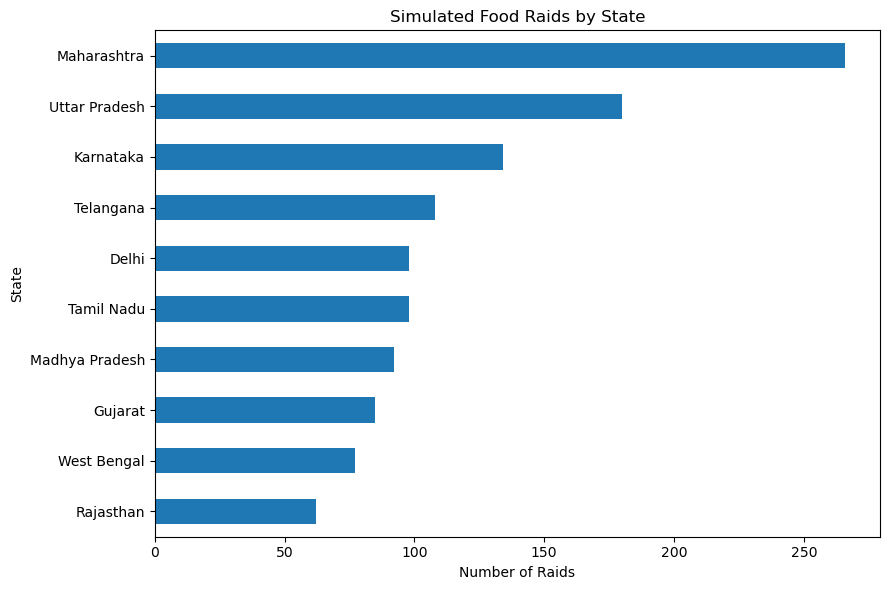

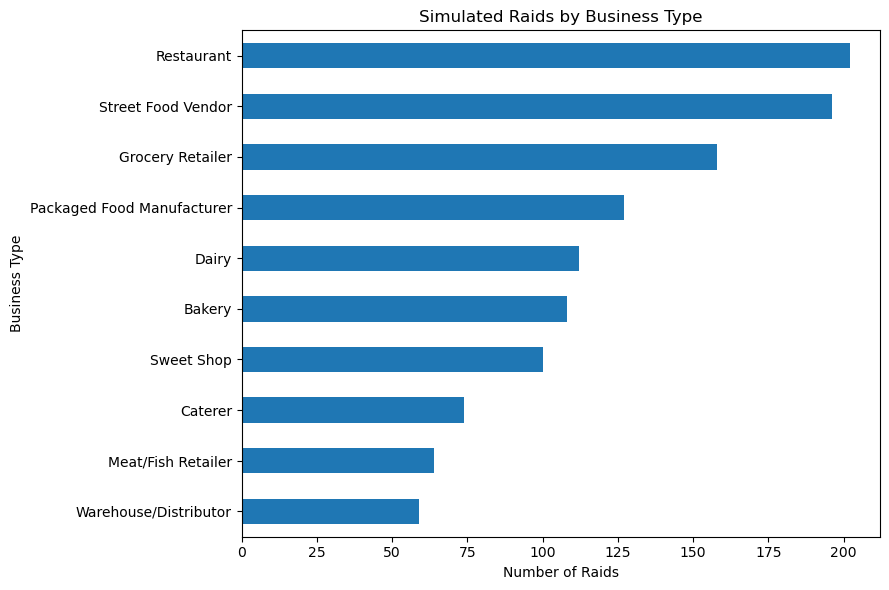

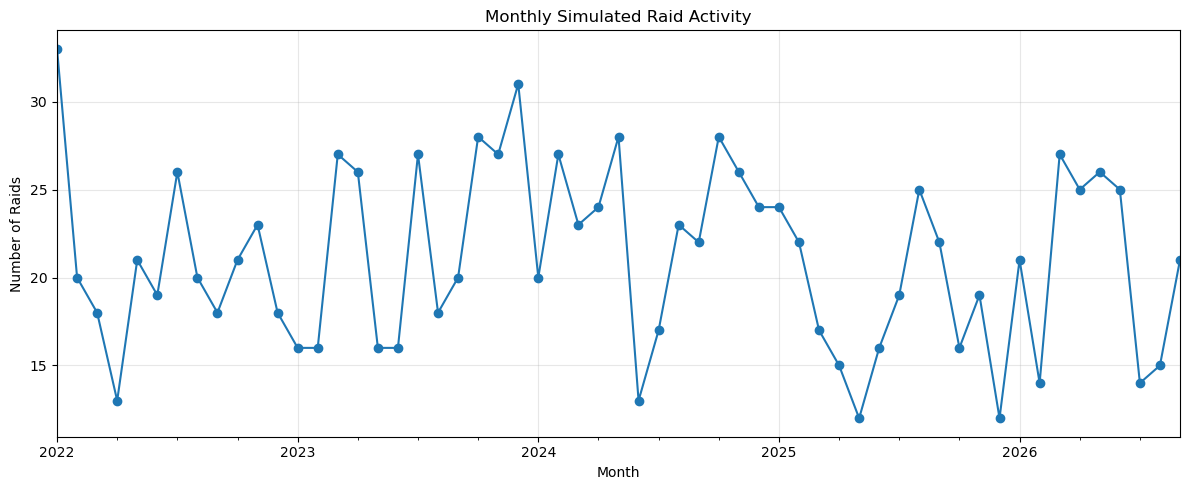

In [21]:

import matplotlib.pyplot as plt

# Prepare state and business information
raid_details = raids.merge(
    businesses[["business_id", "state", "business_type"]],
    on="business_id",
    how="left"
)

# Chart 1: Raids by state
state_counts = raid_details["state"].value_counts().sort_values()

state_counts.plot(kind="barh", figsize=(9, 6))
plt.title("Simulated Food Raids by State")
plt.xlabel("Number of Raids")
plt.ylabel("State")
plt.tight_layout()
plt.show()

# Chart 2: Raids by business type
type_counts = raid_details["business_type"].value_counts().sort_values()

type_counts.plot(kind="barh", figsize=(9, 6))
plt.title("Simulated Raids by Business Type")
plt.xlabel("Number of Raids")
plt.ylabel("Business Type")
plt.tight_layout()
plt.show()

# Chart 3: Monthly raid trend
monthly_counts = (
    raid_details
    .set_index("raid_date")
    .resample("MS")
    .size()
)

monthly_counts.plot(figsize=(12, 5), marker="o")
plt.title("Monthly Simulated Raid Activity")
plt.xlabel("Month")
plt.ylabel("Number of Raids")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [22]:

sample_analysis = (
    samples.groupby("food_category")
    .agg(
        total_samples=("sample_id", "count"),
        non_compliant_samples=(
            "lab_result",
            lambda x: (x == "Non-Compliant").sum()
        )
    )
)

sample_analysis["non_compliance_rate_pct"] = (
    sample_analysis["non_compliant_samples"]
    / sample_analysis["total_samples"] * 100
).round(2)

sample_analysis = sample_analysis.sort_values(
    "non_compliance_rate_pct",
    ascending=False
)

print(sample_analysis)


                 total_samples  non_compliant_samples  non_compliance_rate_pct
food_category                                                                 
Packaged Snacks            172                     33                    19.19
Bakery Products            204                     38                    18.63
Meat/Poultry               179                     31                    17.32
Street Food                178                     30                    16.85
Spices                     197                     31                    15.74
Dairy                      173                     26                    15.03
Beverages                  171                     25                    14.62
Edible Oil                 163                     19                    11.66
Grains/Pulses              158                     18                    11.39
Sweets                     200                     22                    11.00


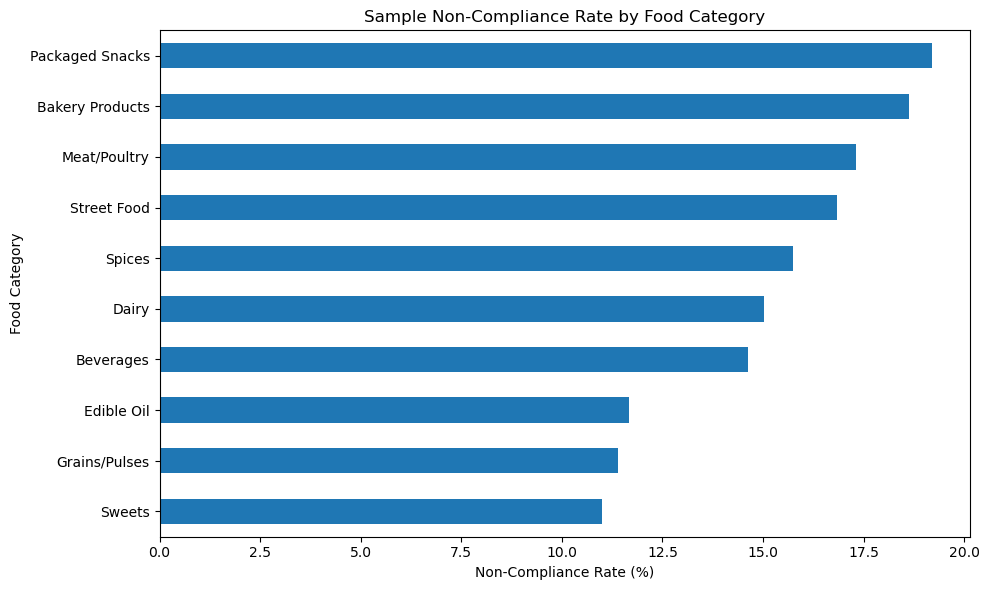

In [23]:

import matplotlib.pyplot as plt

plot_data = sample_analysis.sort_values(
    "non_compliance_rate_pct"
)

plot_data["non_compliance_rate_pct"].plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Sample Non-Compliance Rate by Food Category")
plt.xlabel("Non-Compliance Rate (%)")
plt.ylabel("Food Category")
plt.tight_layout()
plt.show()


Detected Issues in Non-Compliant Samples:
detected_issue
Heavy Metal Above Limit       49
Undeclared Allergen           42
Excess Moisture               40
Synthetic Colour              39
Adulterant Suspected          36
Non-permitted Preservative    35
Microbial Contamination       32
dtype: int64


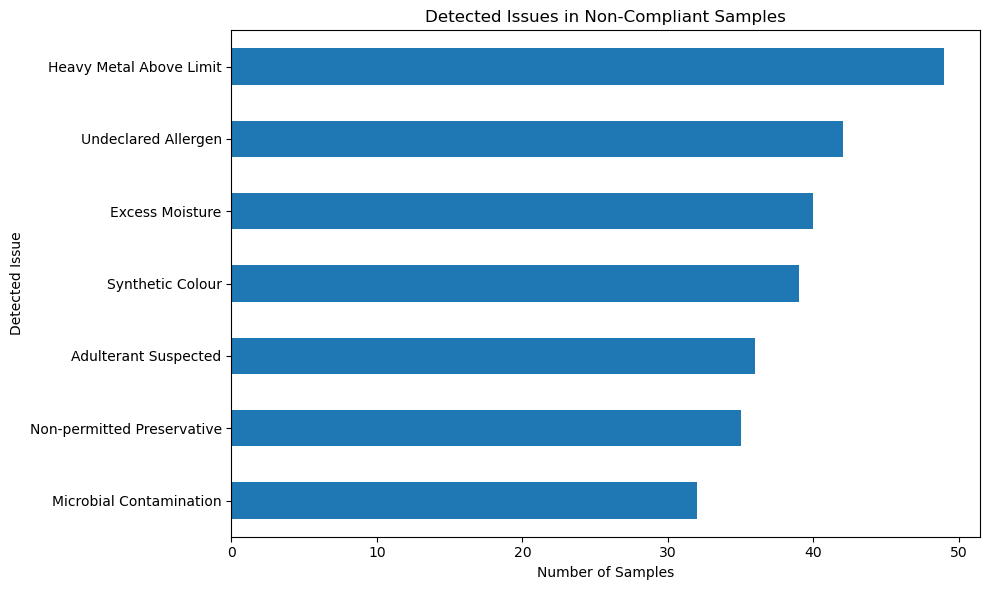

In [24]:

issue_analysis = (
    samples[samples["lab_result"] == "Non-Compliant"]
    .groupby("detected_issue")
    .size()
    .sort_values(ascending=False)
)

print("Detected Issues in Non-Compliant Samples:")
print(issue_analysis)


issue_analysis.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Detected Issues in Non-Compliant Samples")
plt.xlabel("Number of Samples")
plt.ylabel("Detected Issue")
plt.tight_layout()
plt.show()



In [25]:

# Count violations by severity
severity_analysis = (
    violations.groupby("severity")
    .size()
    .sort_values(ascending=False)
)

print("Violations by Severity:")
print(severity_analysis)

# Count violations by type
violation_type_analysis = (
    violations.groupby("violation_type")
    .size()
    .sort_values(ascending=False)
)

print("\nViolations by Type:")
print(violation_type_analysis)


Violations by Severity:
severity
Moderate    301
High        243
Low         202
Critical     81
dtype: int64

Violations by Type:
violation_type
Incorrect Ingredient Declaration    92
Temperature Control Failure         92
Unlicensed Operation                92
Suspected Adulteration              87
Unsafe Water                        86
Mislabeling                         83
Improper Storage                    81
Expired Product                     75
Poor Hygiene                        71
Pest Infestation                    68
dtype: int64


In [26]:

# Summarise violations for each raid
raid_violation_summary = (
    violations.groupby("raid_id")
    .agg(
        violation_count=("violation_id", "count"),
        high_critical_count=(
            "severity",
            lambda x: x.isin(["High", "Critical"]).sum()
        ),
        estimated_violation_fines=("estimated_fine_inr", "sum")
    )
    .reset_index()
)

# Join with enforcement actions
enforcement_analysis = enforcement.merge(
    raid_violation_summary,
    on="raid_id",
    how="left"
)

# Raids without recorded violations get zero counts
enforcement_analysis[
    ["violation_count", "high_critical_count",
     "estimated_violation_fines"]
] = enforcement_analysis[
    ["violation_count", "high_critical_count",
     "estimated_violation_fines"]
].fillna(0)

# Compare actions by violation severity
action_summary = (
    enforcement_analysis.groupby("action_taken")
    .agg(
        raid_count=("raid_id", "nunique"),
        total_fines=("fine_amount_inr", "sum"),
        high_critical_violations=("high_critical_count", "sum")
    )
    .sort_values("raid_count", ascending=False)
)

print(action_summary)


                             raid_count  total_fines  high_critical_violations
action_taken                                                                  
No Further Action                   406            0                      54.0
Warning Issued                      250            0                      51.0
Improvement Notice                  148            0                      52.0
Fine Imposed                        132      3289500                      52.0
Product Seized                      104            0                      50.0
Business Temporarily Closed          61            0                      21.0
Licence Suspended                    55            0                      22.0
Prosecution Initiated                44            0                      22.0


In [27]:

# Find raids with No Further Action
# but with at least one High/Critical violation

suspicious_raids = enforcement_analysis[
    (enforcement_analysis["action_taken"] == "No Further Action") &
    (enforcement_analysis["high_critical_count"] > 0)
]

print("Suspicious raid records:", len(suspicious_raids))

print(
    suspicious_raids[
        [
            "raid_id",
            "action_taken",
            "violation_count",
            "high_critical_count",
            "estimated_violation_fines"
        ]
    ].head(10)
)


Suspicious raid records: 48
    raid_id       action_taken  violation_count  high_critical_count  \
2    R00003  No Further Action              2.0                  1.0   
8    R00009  No Further Action              1.0                  1.0   
10   R00011  No Further Action              1.0                  1.0   
46   R00047  No Further Action              2.0                  2.0   
47   R00048  No Further Action              1.0                  1.0   
60   R00061  No Further Action              1.0                  1.0   
65   R00066  No Further Action              2.0                  1.0   
75   R00076  No Further Action              1.0                  1.0   
79   R00080  No Further Action              1.0                  1.0   
100  R00101  No Further Action              1.0                  1.0   

     estimated_violation_fines  
2                     100000.0  
8                      50000.0  
10                     25000.0  
46                    125000.0  
47            

In [28]:

# One row per raid, with its associated action and severity summary
serious_raids = enforcement_analysis[
    enforcement_analysis["high_critical_count"] > 0
]

no_action_serious = serious_raids[
    serious_raids["action_taken"] == "No Further Action"
]

rate = (
    len(no_action_serious) / len(serious_raids) * 100
    if len(serious_raids) > 0 else 0
)

print("Raids with High/Critical violations:", len(serious_raids))
print("Such raids with No Further Action:", len(no_action_serious))
print("No Further Action rate (%):", round(rate, 2))


Raids with High/Critical violations: 297
Such raids with No Further Action: 48
No Further Action rate (%): 16.16


In [29]:

# Examine the 48 serious raids with No Further Action

investigation = no_action_serious.merge(
    violations[
        [
            "raid_id",
            "violation_type",
            "severity",
            "estimated_fine_inr"
        ]
    ],
    on="raid_id",
    how="left"
)

# Summarise the violations in these cases
print("Severity breakdown:")
print(investigation["severity"].value_counts())

print("\nViolation types:")
print(investigation["violation_type"].value_counts())

print("\nEstimated fines by severity:")
print(
    investigation.groupby("severity")["estimated_fine_inr"]
    .agg(["count", "sum", "mean"])
    .round(2)
)

print("\nSample cases:")
print(
    investigation[
        [
            "raid_id",
            "violation_type",
            "severity",
            "estimated_fine_inr"
        ]
    ].head(15)
)


Severity breakdown:
severity
High        40
Critical    14
Moderate     8
Low          6
Name: count, dtype: int64

Violation types:
violation_type
Temperature Control Failure         10
Incorrect Ingredient Declaration    10
Suspected Adulteration              10
Unlicensed Operation                 8
Improper Storage                     7
Pest Infestation                     6
Mislabeling                          5
Unsafe Water                         5
Poor Hygiene                         4
Expired Product                      3
Name: count, dtype: int64

Estimated fines by severity:
          count      sum      mean
severity                          
Critical     14   184000  13142.86
High         40  1403500  35087.50
Low           6    10000   1666.67
Moderate      8   177500  22187.50

Sample cases:
   raid_id                    violation_type  severity  estimated_fine_inr
0   R00003       Temperature Control Failure       Low                   0
1   R00003              Unlicen

In [33]:

# Rebuild investigation with violation_id included

investigation = no_action_serious.merge(
    violations[
        [
            "violation_id",
            "raid_id",
            "violation_type",
            "severity",
            "estimated_fine_inr"
        ]
    ],
    on="raid_id",
    how="left"
)

# Identify high/critical violations with positive estimated fines
priority_cases = (
    investigation[
        investigation["severity"].isin(["High", "Critical"])
        & (investigation["estimated_fine_inr"] > 0)
    ]
    .groupby("raid_id")
    .agg(
        serious_violation_count=("violation_id", "count"),
        highest_severity=(
            "severity",
            lambda x: "Critical" if (x == "Critical").any() else "High"
        ),
        estimated_fine_total=("estimated_fine_inr", "sum")
    )
    .sort_values("estimated_fine_total", ascending=False)
    .reset_index()
)

print("Priority cases:", len(priority_cases))
print(priority_cases.head(15).to_string(index=False))


Priority cases: 48
raid_id  serious_violation_count highest_severity  estimated_fine_total
 R00047                        2             High                125000
 R01154                        2             High                105000
 R00197                        1             High                100000
 R00999                        1             High                100000
 R00599                        1             High                100000
 R01030                        2             High                100000
 R00817                        1             High                100000
 R00263                        1             High                100000
 R00003                        1             High                100000
 R00387                        2             High                 55000
 R01101                        2         Critical                 52500
 R00868                        1             High                 50000
 R00257                        1         Crit

In [34]:

raid_id_to_check = "R00047"

print("=== RAID DETAILS ===")
print(
    raids[raids["raid_id"] == raid_id_to_check].to_string(index=False)
)

print("\n=== BUSINESS DETAILS ===")
business_id_to_check = raids.loc[
    raids["raid_id"] == raid_id_to_check, "business_id"
].iloc[0]

print(
    businesses[businesses["business_id"] == business_id_to_check]
    .to_string(index=False)
)

print("\n=== VIOLATIONS ===")
print(
    violations[violations["raid_id"] == raid_id_to_check]
    .to_string(index=False)
)

print("\n=== ENFORCEMENT ACTION ===")
print(
    enforcement[enforcement["raid_id"] == raid_id_to_check]
    .to_string(index=False)
)

print("\n=== FOOD SAMPLES ===")
print(
    samples[samples["raid_id"] == raid_id_to_check]
    .to_string(index=False)
)


=== RAID DETAILS ===
raid_id business_id  raid_date        raid_reason inspection_team_id    raid_outcome follow_up_required raid_month
 R00047       B0349 2022-02-17 Routine Inspection           TEAM-002 Seizure/Closure                 No    2022-02

=== BUSINESS DETAILS ===
business_id       business_name business_type    city          state licence_status risk_category business_start_date
      B0349 Gwalior Caterer 349       Caterer Gwalior Madhya Pradesh       Licensed        Medium          2022-10-20

=== VIOLATIONS ===
violation_id raid_id                   violation_type severity  estimated_fine_inr corrective_action_required
     V000027  R00047                      Mislabeling     High               25000                        Yes
     V000028  R00047 Incorrect Ingredient Declaration     High              100000                        Yes

=== ENFORCEMENT ACTION ===
action_id raid_id action_date      action_taken  fine_amount_inr prosecution_status  case_status
   A00047  R

In [35]:

# Identify raids with seizure/closure, corrective action required,
# and no follow-up scheduled.

corrective_raid_ids = set(
    violations.loc[
        violations["corrective_action_required"] == "Yes",
        "raid_id"
    ]
)

consistency_check = raids.merge(
    enforcement[["raid_id", "action_taken", "case_status"]],
    on="raid_id",
    how="left"
)

suspicious = consistency_check[
    (consistency_check["raid_outcome"] == "Seizure/Closure")
    & (consistency_check["follow_up_required"] == "No")
    & (consistency_check["raid_id"].isin(corrective_raid_ids))
]

print("Potentially inconsistent raids:", len(suspicious))
print("\nBreakdown by enforcement action:")
print(suspicious["action_taken"].value_counts())

print("\nDetailed records:")
print(
    suspicious[
        [
            "raid_id",
            "raid_date",
            "raid_outcome",
            "follow_up_required",
            "action_taken",
            "case_status"
        ]
    ].head(20).to_string(index=False)
)


Potentially inconsistent raids: 39

Breakdown by enforcement action:
action_taken
No Further Action              11
Warning Issued                  8
Fine Imposed                    7
Improvement Notice              6
Licence Suspended               2
Business Temporarily Closed     2
Product Seized                  2
Prosecution Initiated           1
Name: count, dtype: int64

Detailed records:
raid_id  raid_date    raid_outcome follow_up_required                action_taken  case_status
 R00031 2022-01-28 Seizure/Closure                 No           No Further Action     Resolved
 R00047 2022-02-17 Seizure/Closure                 No           No Further Action Under Review
 R00077 2022-04-22 Seizure/Closure                 No           No Further Action Under Review
 R00104 2022-05-29 Seizure/Closure                 No                Fine Imposed         Open
 R00162 2022-08-19 Seizure/Closure                 No           Licence Suspended Under Review
 R00248 2022-12-28 Seizure/Clos

In [36]:

# Focus on No Further Action among the 39 flagged raids

no_action_cases = suspicious[
    suspicious["action_taken"] == "No Further Action"
].copy()

# Attach the severity information for each raid
severity_summary = (
    violations.groupby("raid_id")
    .agg(
        high_count=("severity", lambda x: (x == "High").sum()),
        critical_count=("severity", lambda x: (x == "Critical").sum()),
        corrective_required_count=(
            "corrective_action_required",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

no_action_cases = no_action_cases.merge(
    severity_summary,
    on="raid_id",
    how="left"
)

print("Case status breakdown:")
print(no_action_cases["case_status"].value_counts())

print("\nSeverity and case details:")
print(
    no_action_cases[
        [
            "raid_id",
            "case_status",
            "high_count",
            "critical_count",
            "corrective_required_count"
        ]
    ].to_string(index=False)
)


Case status breakdown:
case_status
Resolved        6
Under Review    3
Open            2
Name: count, dtype: int64

Severity and case details:
raid_id  case_status  high_count  critical_count  corrective_required_count
 R00031     Resolved           0               0                          1
 R00047 Under Review           2               0                          2
 R00077 Under Review           0               0                          1
 R00410     Resolved           0               0                          1
 R00507     Resolved           0               0                          1
 R00559 Under Review           0               0                          2
 R00838     Resolved           0               1                          1
 R00868         Open           1               0                          1
 R00892     Resolved           0               0                          1
 R00910     Resolved           0               0                          1
 R01154         Open 

In [37]:

# Create a review-priority classification

no_action_cases["review_priority"] = "Medium"

no_action_cases.loc[
    no_action_cases["case_status"].isin(["Open", "Under Review"])
    & (
        (no_action_cases["high_count"] > 0)
        | (no_action_cases["critical_count"] > 0)
    ),
    "review_priority"
] = "High"

exception_register = no_action_cases[
    [
        "raid_id",
        "case_status",
        "high_count",
        "critical_count",
        "corrective_required_count",
        "review_priority"
    ]
].sort_values(
    ["review_priority", "critical_count", "high_count"],
    ascending=[True, False, False]
)

print(exception_register.to_string(index=False))

print("\nReview priority counts:")
print(exception_register["review_priority"].value_counts())


raid_id  case_status  high_count  critical_count  corrective_required_count review_priority
 R00047 Under Review           2               0                          2            High
 R01154         Open           2               0                          2            High
 R00868         Open           1               0                          1            High
 R00838     Resolved           0               1                          1          Medium
 R00031     Resolved           0               0                          1          Medium
 R00077 Under Review           0               0                          1          Medium
 R00410     Resolved           0               0                          1          Medium
 R00507     Resolved           0               0                          1          Medium
 R00559 Under Review           0               0                          2          Medium
 R00892     Resolved           0               0                          1     

In [38]:

priority_order = {"High": 1, "Medium": 2}

exception_register["priority_rank"] = (
    exception_register["review_priority"].map(priority_order)
)

exception_register = (
    exception_register
    .sort_values(
        ["priority_rank", "critical_count", "high_count"],
        ascending=[True, False, False]
    )
    .drop(columns="priority_rank")
)

print(exception_register.to_string(index=False))
print("\nPriority counts:")
print(
    exception_register["review_priority"]
    .value_counts()
)


raid_id  case_status  high_count  critical_count  corrective_required_count review_priority
 R00047 Under Review           2               0                          2            High
 R01154         Open           2               0                          2            High
 R00868         Open           1               0                          1            High
 R00838     Resolved           0               1                          1          Medium
 R00031     Resolved           0               0                          1          Medium
 R00077 Under Review           0               0                          1          Medium
 R00410     Resolved           0               0                          1          Medium
 R00507     Resolved           0               0                          1          Medium
 R00559 Under Review           0               0                          2          Medium
 R00892     Resolved           0               0                          1     

In [39]:

# Summarise violation information at raid level
violation_summary = (
    violations.groupby("raid_id")
    .agg(
        high_count=("severity", lambda x: (x == "High").sum()),
        critical_count=("severity", lambda x: (x == "Critical").sum()),
        corrective_required_count=(
            "corrective_action_required",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

# Build one row per raid
audit = (
    raids.merge(
        enforcement[["raid_id", "action_taken", "case_status"]],
        on="raid_id",
        how="left"
    )
    .merge(violation_summary, on="raid_id", how="left")
)

count_cols = [
    "high_count", "critical_count", "corrective_required_count"
]
audit[count_cols] = audit[count_cols].fillna(0)

# Define audit rules
audit["serious_no_action"] = (
    ((audit["high_count"] + audit["critical_count"]) > 0)
    & (audit["action_taken"] == "No Further Action")
)

audit["correction_no_followup"] = (
    (audit["corrective_required_count"] > 0)
    & (audit["follow_up_required"] == "No")
)

audit["unresolved_no_action"] = (
    audit["case_status"].isin(["Open", "Under Review"])
    & (audit["action_taken"] == "No Further Action")
)

audit["flag_count"] = audit[
    [
        "serious_no_action",
        "correction_no_followup",
        "unresolved_no_action"
    ]
].sum(axis=1)

print("Total raids audited:", len(audit))
print("\nFlag counts by rule:")
print(audit[
    [
        "serious_no_action",
        "correction_no_followup",
        "unresolved_no_action"
    ]
].sum())

print("\nRaids with at least one flag:", (audit["flag_count"] > 0).sum())


Total raids audited: 1200

Flag counts by rule:
serious_no_action          48
correction_no_followup    203
unresolved_no_action      187
dtype: int64

Raids with at least one flag: 391


In [40]:

# Create readable reasons for each flagged raid

def get_flag_reasons(row):
    reasons = []

    if row["serious_no_action"]:
        reasons.append("High/Critical violation + No Further Action")

    if row["correction_no_followup"]:
        reasons.append("Corrective action required + No follow-up")

    if row["unresolved_no_action"]:
        reasons.append("Unresolved case + No Further Action")

    return " | ".join(reasons)


audit["exception_reason"] = audit.apply(get_flag_reasons, axis=1)

# Keep only flagged raids
exception_register_all = audit[
    audit["flag_count"] > 0
].copy()

# Assign review priority using transparent screening rules
exception_register_all["review_priority"] = "Low"

exception_register_all.loc[
    exception_register_all["serious_no_action"],
    "review_priority"
] = "High"

exception_register_all.loc[
    exception_register_all["unresolved_no_action"]
    & (exception_register_all["review_priority"] != "High"),
    "review_priority"
] = "Medium"

# Sort High, then Medium, then Low
priority_order = {"High": 1, "Medium": 2, "Low": 3}

exception_register_all["priority_rank"] = (
    exception_register_all["review_priority"].map(priority_order)
)

exception_register_all = exception_register_all.sort_values(
    ["priority_rank", "flag_count"],
    ascending=[True, False]
)

print("Total exceptions:", len(exception_register_all))

print("\nPriority breakdown:")
print(exception_register_all["review_priority"].value_counts())

print("\nSample exception register:")
print(
    exception_register_all[
        [
            "raid_id",
            "raid_date",
            "raid_outcome",
            "follow_up_required",
            "action_taken",
            "case_status",
            "flag_count",
            "exception_reason",
            "review_priority"
        ]
    ].head(15).to_string(index=False)
)


Total exceptions: 391

Priority breakdown:
review_priority
Low       179
Medium    164
High       48
Name: count, dtype: int64

Sample exception register:
raid_id  raid_date     raid_outcome follow_up_required      action_taken  case_status  flag_count                                                                                                              exception_reason review_priority
 R00003 2022-01-02  Violation Found                 No No Further Action Under Review           3 High/Critical violation + No Further Action | Corrective action required + No follow-up | Unresolved case + No Further Action            High
 R00047 2022-02-17  Seizure/Closure                 No No Further Action Under Review           3 High/Critical violation + No Further Action | Corrective action required + No follow-up | Unresolved case + No Further Action            High
 R00307 2023-03-27  Violation Found                 No No Further Action Under Review           3 High/Critical violation + N

In [41]:

# Count how many raids trigger each combination of rules

flag_columns = [
    "serious_no_action",
    "correction_no_followup",
    "unresolved_no_action"
]

flag_combinations = (
    audit[audit["flag_count"] > 0]
    .groupby(flag_columns, dropna=False)
    .size()
    .reset_index(name="raid_count")
    .sort_values("raid_count", ascending=False)
)

print(flag_combinations.to_string(index=False))


 serious_no_action  correction_no_followup  unresolved_no_action  raid_count
             False                    True                 False         179
             False                   False                  True         154
              True                   False                 False          18
              True                   False                  True          16
             False                    True                  True          10
              True                    True                 False           7
              True                    True                  True           7


In [42]:

exception_register_all.to_csv(
    "fssai_exception_register_all.csv",
    index=False
)

print("CSV file saved successfully!")


CSV file saved successfully!
